# Análise de dados de hipotireoidismo
Trabalho de Ciência de Dados

### O objetivo do Trabalho

Meu objetivo neste trabalho é classificar os registros da base Hypothyroid nas classes P e N, usando dados dos pacientes e resultados dos exames.   
A variável-alvo é `binaryClass`, e o problema é de classificação supervisionada. Como a classe N é minoritária, vou analisar principalmente o recall e a precisão dessa classe, além da acurácia. 
A idéia aqui é verificar se os dados disponíveis permitem identificar registros na classe N que poderiam ser encaminhados para um revisão posterior. 

### Escolha da Base

Optei pela base de hipotireoidismo porque permite trabalhar com classificação supervisionada usando variáveis numéricas e categóricas.
Esta base também apresenta problemas comuns em projetos de Ciência de dados, como valores ausentes e classes desbalanceadas. 
Essas características permitem comparar modelos e avaliar se a acurácia, por si só, representa adequadamente os resultados. 

# 1. Leitura e limpeza

A variável-alvo é `binaryClass`, com as classes P e N. O CSV não explica esses códigos, mas a documentação da base Hypothyroid indica que se trata de uma classificação relacionada ao hipotireoidismo. Neste trabalho, considerei N como a classe de interesse devido a sua baixa frequência.

Usei a base Hypothyroid do OpenML (ID 1000), indicada no link abaixo, para entender o contexto de P e N.

- OpenML. *Hypothyroid*, conjunto de dados ID 1000. https://www.openml.org/search?type=data&sort=runs&status=active&id=1000

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, precision_score, ConfusionMatrixDisplay

dados = pd.read_csv("Base_M43_Pratique_Hypothyroid.csv", na_values="?")
print("Formato original:", dados.shape)
print("Linhas duplicadas:", dados.duplicated().sum())
dados = dados.drop_duplicates().copy()
numericas = ["age", "TSH", "T3", "TT4", "T4U", "FTI"]
for coluna in numericas:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")
# Idade 455 não faz sentido; tratei como ausente
dados.loc[(dados["age"] < 0) | (dados["age"] > 120), "age"] = np.nan
print("Após limpeza:", dados.shape)
print(dados["binaryClass"].value_counts())
print("Ausentes nas variáveis usadas:")
print(dados[numericas + ["sex"]].isna().sum())
print("Percentual de ausentes:")
print(
    (dados.isna().mean() * 100)
    .sort_values(ascending=False)
    .round(1)
)

print("Colunas totalmente vazias:")
print(dados.columns[dados.isna().all()].tolist())

Formato original: (3772, 30)
Linhas duplicadas: 61
Após limpeza: (3711, 30)
binaryClass
P    3420
N     291
Name: count, dtype: int64
Ausentes nas variáveis usadas:
age      2
TSH    309
T3     709
TT4    171
T4U    327
FTI    325
sex    149
dtype: int64
Percentual de ausentes:
TBG                          100.0
T3                            19.1
T4U                            8.8
FTI                            8.8
TSH                            8.3
TT4                            4.6
sex                            4.0
age                            0.1
referral source                0.0
TBG measured                   0.0
FTI measured                   0.0
T4U measured                   0.0
TT4 measured                   0.0
T3 measured                    0.0
TSH measured                   0.0
psych                          0.0
hypopituitary                  0.0
tumor                          0.0
goitre                         0.0
lithium                        0.0
query hyperthyroid   

### Qualidade dos dados

A base original possui 3.772 registros. Após remover 61 duplicatas, restaram 3.711 registros. Encontrei uma idade de 455 anos e tratei este valor como ausente, pois não era uma idade válida. A coluna TBG estava totalmente vazia, então não usei no modelo. Os demais valores ausentes foram preenchidos dentro do Pipeline, usando os dados de treinamento para calcular os valores necessários. 

# 2. Classes e TSH
P tem muito mais registros que N. Comparei com um Dummy (prevê apenas P) para ter um piso.

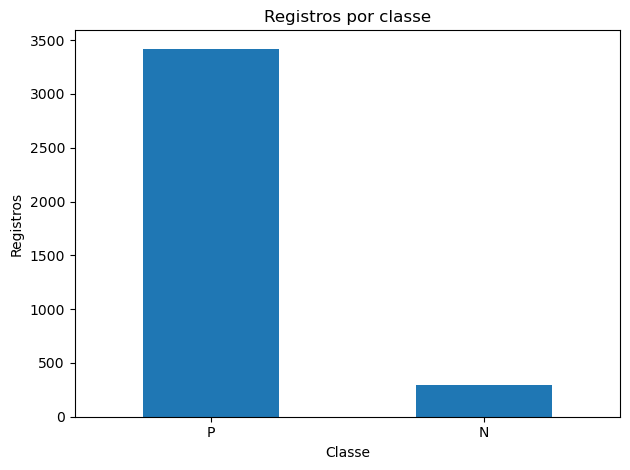

In [5]:
contagem = dados["binaryClass"].value_counts().reindex(["P", "N"])
ax = contagem.plot(kind="bar", rot=0, title="Registros por classe")
ax.set(xlabel="Classe", ylabel="Registros")
plt.tight_layout()
plt.show()

### Estatística descritiva dos exames

In [6]:

estatisticas = dados[["TSH", "T3", "TT4", "T4U", "FTI"]].describe()

print(estatisticas.round(2))


           TSH       T3      TT4      T4U      FTI
count  3402.00  3002.00  3540.00  3384.00  3386.00
mean      5.09     2.01   108.33     0.99   110.48
std      24.52     0.83    35.61     0.20    33.09
min       0.00     0.05     2.00     0.25     2.00
25%       0.50     1.60    88.00     0.88    93.00
50%       1.40     2.00   103.00     0.98   107.00
75%       2.70     2.40   124.00     1.08   124.00
max     530.00    10.60   430.00     2.32   395.00


In [7]:

medianas = dados.groupby("binaryClass")[["TSH", "T3", "TT4", "T4U", "FTI"]].median()

print(medianas.round(2))


              TSH   T3    TT4   T4U    FTI
binaryClass                               
N            12.0  1.5   76.5  1.01   77.5
P             1.2  2.0  105.0  0.97  108.5


A mediana do TSH foi 12,0 na classe N e 1,2 na classe P. Já o TT4 caiu de 105,0 em P para 76,5 em N.

Olhando esses resultados, percebi diferenças entre as classes, principalmente no TSH. Por isso mantive esses exames entre as variáveis dos modelos. 

### Distribuição dos exames

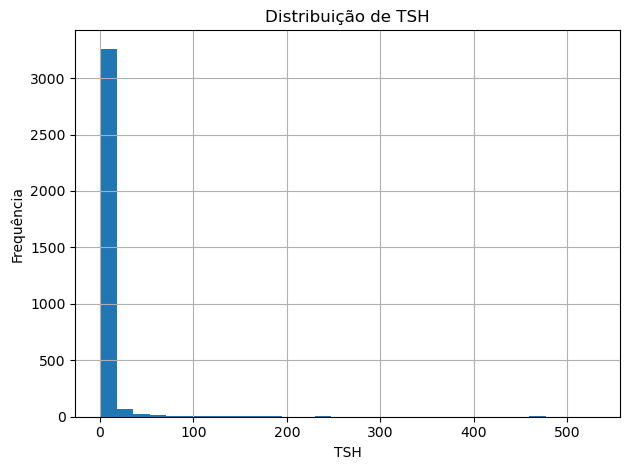

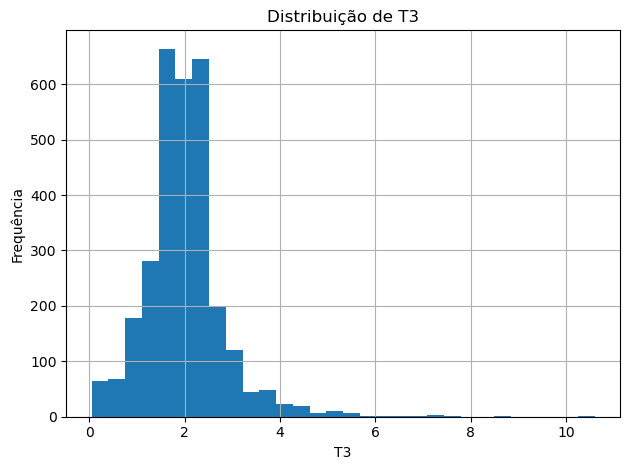

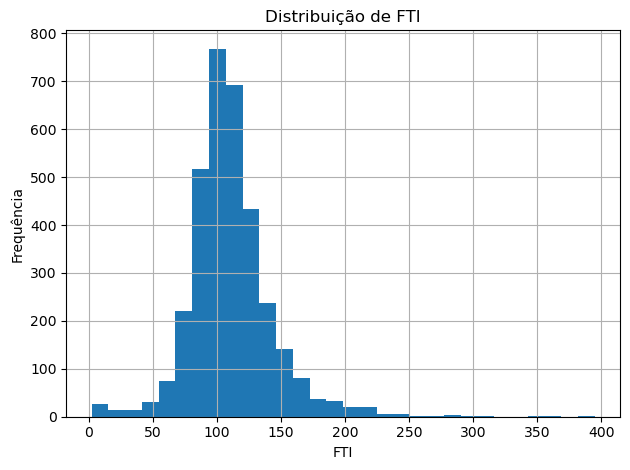

In [8]:

for coluna in ["TSH", "T3", "FTI"]:
    dados[coluna].hist(bins=30)
    plt.title("Distribuição de " + coluna)
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()


O TSH apresentou maior assimetria, com média de 5,09, mediana de 1,40 e valor máximo de 530. Já o T3 apresentou valores mais concentrados, com média de 2,01 e mediana de 2,00. O FTI chegou a 395, mas apresentou menor assimetria que o TSH. No TSH, a diferença entre média e mediana mostra como os valores mais altos afetam a distribuição. 

### Correlação entre as variáveis

      TSH    T3   TT4   T4U   FTI
TSH  1.00 -0.16 -0.27  0.07 -0.30
T3  -0.16  1.00  0.56  0.45  0.35
TT4 -0.27  0.56  1.00  0.43  0.79
T4U  0.07  0.45  0.43  1.00 -0.17
FTI -0.30  0.35  0.79 -0.17  1.00


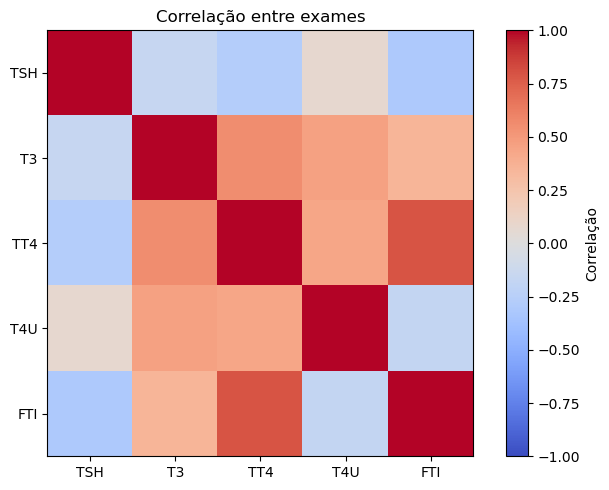

In [9]:

colunas = ["TSH", "T3", "TT4", "T4U", "FTI"]

correlacao = dados[colunas].corr()

print(correlacao.round(2))

plt.figure(figsize=(7, 5))
plt.imshow(correlacao, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlação")
plt.xticks(range(len(colunas)), colunas)
plt.yticks(range(len(colunas)), colunas)
plt.title("Correlação entre exames")
plt.tight_layout()
plt.show()


A maior correlação encontrada foi entre TT4 e FTI, com coeficiente de 0,79.
Essa correlação é esperada, pois o FTI é calculado a partir do T4 total e de uma medida relacionada à ligação dos hormônios da tireoide. 

Também encontrei correlação positiva de 0,56 entre T3 e TT4.

O TSH apresentou correlações negativas com alguns exames, como FTI (-0,30) e TT4 (-0,27).

Mantive todos esses exames como variáveis de entrada, mesmo com a correlação encontrada entre alguns deles.

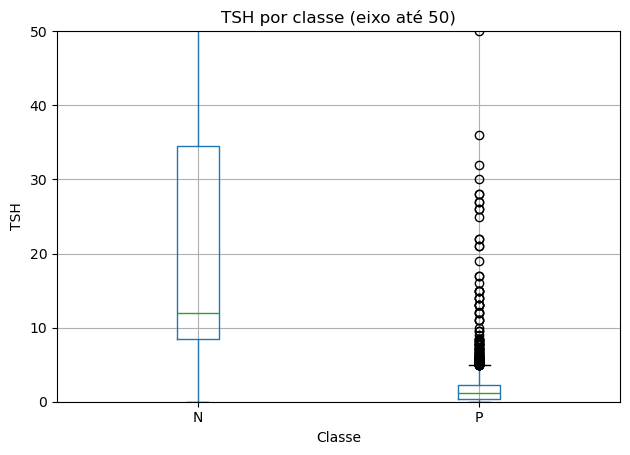

In [10]:
ax = dados.boxplot(column="TSH", by="binaryClass")
plt.ylim(0, 50)
plt.suptitle("")
plt.title("TSH por classe (eixo até 50)")
plt.xlabel("Classe")
plt.ylabel("TSH")
plt.tight_layout()
plt.show()

Limitei o eixo Y do boxplot a 50 porque o TSH chega a 530, dificultando a visualização dos demais valores. Os registros extremos foram mantidos nos dados usados pelos modelos. 

## Resumo da análise exploratória

Após a limpeza, ficaram 3.711 registros, sendo 291 da classe N (7,8%). A mediana do TSH foi 12,0 em N e 1,2 em P. Também encontrei valores extremos nos exames e correlação de 0,79 entre TT4 e FTI.

Como a classe N é minoritária, utilizei recall e precisão além da acurácia na avaliação dos modelos. 

# 3. Treino e comparação

### Preparação dos dados

Separei 75% dos registros para treinamento e 25% para teste, usando a divisão estratificada para manter a proporção das classes. 

No Pipeline, preenchi os valores ausentes das variáveis numéricas pela mediana e fiz a padronização. Para sexo, utilizei a categoria mais frequente e a codificação numérica. O preenchimento e a padronização foram ajustados com os dados de treinamento. 

Usei class_weight="balanced" na regressão logística e na árvore de decisão para considerar o desbalanceamento das classes. Na árvore, defini max_depth=5 para limitar a profundidade e min_samples_leaf=10 para exigir pelo menos dez registros em cada folha. 

Utilizei idade, sexo e exames laboratoriais como variáveis de entrada. Não incluí informações sobre tratamento, encaminhamento ou suspeitas clínicas, pois não foi possível confirmar se estariam disponíveis no momento da classificação.

In [11]:
X = dados[numericas + ["sex"]]
y = dados["binaryClass"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_treino, y_treino)

preparo = ColumnTransformer([
    ("num", Pipeline([
        ("preencher", SimpleImputer(strategy="median")),
        ("padronizar", StandardScaler())
    ]), numericas),
    ("cat", Pipeline([
        ("preencher", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore"))
    ]), ["sex"])
])
modelo = Pipeline([
    ("preparo", preparo),
    ("regressao", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
modelo.fit(X_treino, y_treino);



In [12]:
arvore = Pipeline([
    ("preparo", preparo),
    ("classificador", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

arvore.fit(X_treino, y_treino);

In [16]:

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nome, classificador in {
    "Regressão logística": modelo,
    "Árvore de decisão": arvore
}.items():

    notas = cross_val_score(
        classificador,
        X_treino,
        y_treino,
        cv=validacao,
        scoring="balanced_accuracy"
    )

    print(nome)
    print("Média:", round(notas.mean(), 3))
    print("Desvio-padrão:", round(notas.std(), 3))


Regressão logística
Média: 0.953
Desvio-padrão: 0.027
Árvore de decisão
Média: 0.985
Desvio-padrão: 0.004


### Validação cruzada e escolha do modelo


Utilizei validação cruzada com cinco divisões estratificadas dos dados de treinamento para comparar a regressão logística e a árvore de decisão.

- A regressão logística apresentou acurácia balanceada média de 95,3%, com desvio-padrão de 2,7 pontos percentuais.

- A árvore de decisão apresentou acurácia balanceada média de 98,5%, com desvio padrão de 0,4 ponto percentual. 

Escolhi a árvore para avaliação final porque teve a maior acurácia balanceada média (98,5%) e a menor variação na validação cruzada. Fiz essa escolha antes de avaliar os resultados do conjunto de teste. 

In [18]:

previsao_arvore = arvore.predict(X_teste)

comparacao = []

modelos = {
    "Dummy": dummy,
    "Regressão logística": modelo,
    "Árvore de decisão": arvore
}

for nome, classificador in modelos.items():
    pred = classificador.predict(X_teste)

    comparacao.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, pred),
        "Recall N": recall_score(y_teste, pred, pos_label="N", zero_division=0),
        "Precisão N": precision_score(
            y_teste, pred, pos_label="N",
            zero_division=0
        ),
        "Acurácia balanceada": balanced_accuracy_score(y_teste, pred)
    })

tabela = pd.DataFrame(comparacao)
tabela.round(3)


,Modelo,Acurácia,Recall N,Precisão N,Acurácia balanceada
0,Dummy,0.921,0.000,0.000,0.500
1,Regressão logística,0.967,0.945,0.719,0.957
2,Árvore de decisão,0.978,0.986,0.791,0.982


In [13]:

from sklearn.metrics import average_precision_score

posicao_n = list(arvore.classes_).index("N")
prob_n = arvore.predict_proba(X_teste)[:, posicao_n]

real_n = (y_teste == "N").astype(int)

ap_n = average_precision_score(real_n, prob_n)

print(f"Average Precision da classe N: {ap_n:.3f}")


Average Precision da classe N: 0.867


### Avaliação por precisão-recall

A Average Precision da classe N foi de 0,867. Usei essa métrica para avaliar a relação entre precisão e recall em diferentes pontos de corte, além dos resultados já apresentados para o teste. 

### Comparação dos modelos

O Dummy teve acurácia elevada, mas não identificou nenhum registro N. A regressão logística conseguiu identificar a maior parte dessa classe, enquanto a árvore apresentou o melhor recall. Por isso, mantive a árvore como modelo principal. 

In [20]:

nomes = modelo.named_steps["preparo"].get_feature_names_out()

coeficientes = modelo.named_steps["regressao"].coef_[0]

classe_coeficiente = modelo.named_steps["regressao"].classes_[1]

importancia = pd.DataFrame({
    "Variável": nomes,
    "Coeficiente": coeficientes
})

importancia["Magnitude"] = importancia["Coeficiente"].abs()

importancia = importancia.sort_values(
    "Magnitude", ascending=False
)

print("Classe associada aos coeficientes positivos:", classe_coeficiente)
importancia.round(3)


Classe associada aos coeficientes positivos: P


,Variável,Coeficiente,Magnitude
1,num__TSH,-11.973,11.973
3,num__TT4,1.510,1.510
4,num__T4U,-0.846,0.846
5,num__FTI,-0.549,0.549
7,cat__sex_M,0.300,0.300
2,num__T3,0.224,0.224
6,cat__sex_F,0.096,0.096
0,num__age,-0.018,0.018


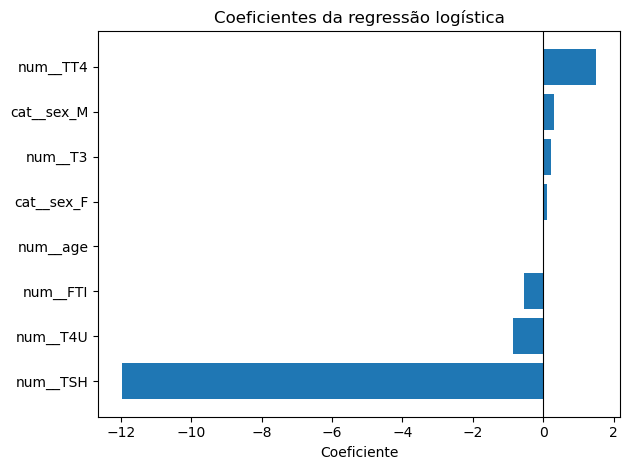

In [15]:

grafico = importancia.sort_values("Coeficiente")

plt.barh(grafico["Variável"], grafico["Coeficiente"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Coeficientes da regressão logística")
plt.xlabel("Coeficiente")
plt.tight_layout()
plt.show()


### Análise complementar dos coeficientes da regressão logística

Neste ponto, também analisei os coeficientes da regressão logística para entender melhor as variáveis utilizadas pelo modelo. 

Os coeficientes positivos favorecem a classe P e os negativos favorecem a classe N. O TSH apresentou o maior coeficiente em magnitude(-11,973), seguido pelo TT4(1,510). Esses dois exames tiveram coeficientes maiores que os de idade e sexo. 

Esses valores mostram associações dentro da regressão logística, não relações de causa e efeito. 
Também não apresentam a importância das variáveis na árvore de decisão. 

In [16]:
nomes_arvore = arvore.named_steps["preparo"].get_feature_names_out()
valores = arvore.named_steps["classificador"].feature_importances_

importancia_arvore = pd.DataFrame({
    "Variável": nomes_arvore,
    "Importância": valores
}).sort_values("Importância", ascending=False)

print(importancia_arvore.round(6))

     Variável  Importância
1    num__TSH     0.985559
3    num__TT4     0.013823
5    num__FTI     0.000378
2     num__T3     0.000240
4    num__T4U     0.000000
0    num__age     0.000000
6  cat__sex_F     0.000000
7  cat__sex_M     0.000000


### A importância das variáveis na árvore de decisão

Usei feature_importances_ para verificar quais variáveis tiveram maior participação nas divisões da árvore.

O TSH apresentou maior importância, com 98,56% do total. Em seguida apareceram o TT4, com 1,38%, o FTI com 0,04% e o T3 com 0,02%.

O T4U, a idade e o sexo tiveram importância igual a zero, indicando que não foram utilizados nas divisões dessa árvore.

Essas importâncias mostram quais variáveis a árvore mais utilizou para fazer as classificações nesta base. Não representam, necessariamente, a importância clínica de cada exame.

# 4. Matriz de confusão

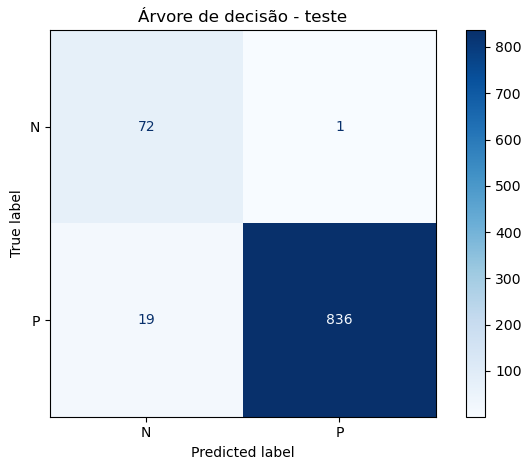

In [17]:

ConfusionMatrixDisplay.from_predictions(
    y_teste, previsao_arvore,
    labels=["N", "P"],
    cmap="Blues"
)
plt.title("Árvore de decisão - teste")
plt.tight_layout()
plt.show()


A árvore de decisão identificou corretamente 72 dos 73 registros na classe N, atingindo recall de 98,6%. Apenas um registro N foi classificado como P, enquanto 19 registros P foram classificados como N. A precisão para classe N foi de 79,1%  e a acurácia geral chegou a 97,8%.

Como a classe N é minoritária, considerei o recall e a precisão junto com a acurácia para avaliar o modelo. 

# 5. Conferência de erros
Separei as previsões erradas para conferir os valores de TSH e FTI. Os números das linhas são os índices preservados do CSV após retirar duplicatas.

In [18]:
erros = X_teste.loc[previsao_arvore != y_teste].copy()
erros["real"] = y_teste.loc[erros.index]
erros["previsto"] = previsao_arvore[previsao_arvore != y_teste]

print("N previstos como P:")
print(erros.loc[
    erros["real"] == "N",
    ["TSH", "FTI", "real", "previsto"]
].head(4).to_string())

print("\nP previstos como N (exemplos):")
print(erros.loc[
    erros["real"] == "P",
    ["TSH", "FTI", "real", "previsto"]
].head(3).to_string())

N previstos como P:
      TSH   FTI real previsto
2735  4.6  54.0    N        P

P previstos como N (exemplos):
         TSH   FTI real previsto
2766   0.015   NaN    P        N
1450   4.700  17.0    P        N
1174  21.000  84.0    P        N


A árvore de decisão classificou incorretamente um registro da classe N e 19 registros da classe P.

O registro N previsto como P foi o da linha 2735, com TSH de 4,6 e FTI de 54.

Entre os registros P previstos como N, a linha 1450 apresentou TSH de 4,7 e FTI de 17, enquanto a linha 1174 apresentou TSH de 21 e FTI de 84.

Esses exemplos mostram que o modelo ainda comete erros de classificação. Não é possível afirmar que os registros possuem rótulos incorretos apenas com base nessas previsões.

## 6. Conclusão

### Resultados

Após retirar 61 duplicatas, ficaram 3.711 registros, sendo 3.420 da classe P e 291 da classe N. 

Comparei o Dummy, a regressão logística e a árvore de decisão.

O Dummy apresentou acurácia de 92,1%, mas não identificou nenhum registro da classe N.

Na validação cruzada, a árvore apresentou acurácia balanceada de 98,5%, enquanto a regressão logística apresentou 95,3%. Por este motivo, escolhi a árvore de decisão para a avaliação final.

No conjunto de teste, a árvore apresentou acurácia de 97,8%, recall de 98,6% e precisão de 79,1% para a classe N. 

Dos 73 registros N presentes no teste, o modelo identificou corretamente 72. Apenas um registro N foi classificado como P, enquanto 19 registros P foram classificados como N.


### Limitações

A base tem só 291 registros N. No teste, são 73 casos N. Um erro de 1 caso muda o recall em cerca de 1,4 ponto percentual. Por isso, o resultado precisa ser lido com cautela e não deve ser generalizado sem validação externa. 


### Recomendação prática

O modelo pode ajudar sim a selecionar registros para revisão, mas não deve ser utilizado para diagnóstico clínico sem avaliação profissional.
Neste cenário, um falso negativo poderia deixar um registro da classe N sem a revisão esperada, enquanto um falso positivo poderia gerar uma análise adicional desnecessária.


Antes de uma aplicação real, seria necessário confirmar o significado clínico das classes. 

**Fontes usadas:** CSV fornecido para o exercício e documentação do scikit-learn para os classificadores e métricas.